# Notebook 04. CODA: does cough audio add value when the country changes?

**The study as proposed.** CODA holds solicited coughs from 1,105 adults in seven countries, all recorded with the same phone app. Holding out one country at a time while keeping the recording procedure the same is the clean test of our question:

> When a whole country is left out of model development, does adding cough audio to routine clinical questions improve TB triage?

**What this notebook does (Week 1 of the plan).**

| Step | Output |
|---|---|
| 1 | Connect to the private Azure container and find the CODA files |
| 2 | Participant table: TB label, the 9 shared clinical variables, CODA's extra variables, country |
| 3 | EDA: participants and TB rate per country, coughs per person, questionnaire answers |
| 4 | Test groups for leave-one-country-out, merging countries with too few TB cases |
| 5 | Load and check the 9,772 coughs; keep 16 kHz waveforms for later encoders |
| 6 | Three representations: MFCC summary, spectrogram summary, pretrained VGGish |
| 7 | Random participant split: the in-distribution reference |
| 8 | Leave-one-country-out: questionnaire (B), cough, combined (A), gain Δ, worst country, frozen threshold |
| 9 | How optimistic the random split is, and whether a cough reveals its country |
| 10 | Summary and export (aggregate results only) |

**Data protection.** CODA is controlled-access. This notebook reads it straight from your private Azure container and caches it only inside this private Kaggle session. It never creates a Kaggle dataset, and the export bundle contains only aggregate tables and figures: no audio, no embeddings and no per-participant predictions.

**Kaggle settings.** Keep the notebook **private**. GPU T4 (only Step 6 uses it). Internet ON. Secret: `AZURE_STORAGE_CONNECTION_STRING`.

In [1]:
import os, io, re, sys, json, time, copy, zipfile, itertools, subprocess, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import soundfile as sf, librosa
from scipy.stats import norm
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import roc_auc_score, roc_curve, balanced_accuracy_score
from sklearn.manifold import TSNE
from IPython.display import display
warnings.filterwarnings("ignore")

TEST_MODE = os.environ.get("CODA_TEST_MODE") == "1"
CFG = dict(
    AZURE_CONTAINER   = "coda",
    PREFIX            = "v1/Train/",
    LOCAL_STORE       = None,          # offline testing only
    WORK_DIR          = "/kaggle/working",
    CLIP_SECONDS      = 0.5,           # CODA's native clip length; every clip is trimmed or padded to this
    MIN_DETECTOR_SCORE = 0.0,          # optionally drop coughs the Hyfe detector was less sure about (all are >= 0.85)
    MIN_TB_PER_GROUP  = 15,            # a held-out group needs at least this many TB cases; smaller countries are merged
    SENSITIVITY_TARGET = 0.90,         # WHO triage target, used for the frozen threshold
    N_FOLDS           = 5,
    PROBE_C           = 0.1,
    CLIN_C            = 1.0,
    DOWNLOAD_WORKERS  = 32,
    N_BOOT            = 1000,
    EXPORT_EMBEDDINGS = False,         # keep False: derived audio features stay inside this private session
    SEED              = 42,
)
if TEST_MODE:
    CFG.update(LOCAL_STORE="/home/claude/coda/fixture", WORK_DIR="/home/claude/coda/work", N_BOOT=200, MIN_TB_PER_GROUP=6)

WORK = Path(CFG["WORK_DIR"]); OUT = WORK / "outputs_coda"; CACHE = WORK / "cache_coda"; FIG_DIR = OUT / "figures"
for d in (OUT, CACHE, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(CFG["SEED"])
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

if not hasattr(plt, "_true_show"):                        # remember the real plt.show only once
    plt._true_show = plt.show
_fig_no = [0]
def _show_and_save(*args, **kwargs):                      # every figure shown is also saved for the report
    for num in plt.get_fignums():
        fig = plt.figure(num)
        title = fig._suptitle.get_text() if getattr(fig, "_suptitle", None) else (fig.axes[0].get_title() if fig.axes else "")
        _fig_no[0] += 1
        slug = re.sub(r"[^a-z0-9]+", "_", title.lower()).strip("_")[:60] or "figure"
        fig.savefig(FIG_DIR / f"{_fig_no[0]:02d}_{slug}.png", dpi=150, bbox_inches="tight")
    plt._true_show(*args, **kwargs)
plt.show = _show_and_save

try:
    import torch, torch.nn as nn
    TORCH_OK, DEVICE = True, ("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(CFG["SEED"])
except ImportError:
    TORCH_OK, DEVICE = False, "cpu"
print(f"Test mode: {TEST_MODE} | PyTorch: {TORCH_OK} | device: {DEVICE}")

Test mode: False | PyTorch: True | device: cuda


## Step 1. Connect to the private Azure container

The CODA files sit in the container `coda` under `v1/Train/`: the clinical tables in `meta_data/Clinical/`, the cough-to-participant table in `meta_data/Cough Metadata/`, and the 9,772 solicited coughs in `raw_data/solicited_data/`. Files are found by name, so small differences in folder names do not matter.

In [2]:
class LocalStore:
    def __init__(self, root):
        self.root = Path(root)
    def list(self, prefix):
        p = self.root / prefix
        for f in sorted(p.rglob("*")) if p.is_dir() else []:
            if f.is_file():
                yield f.relative_to(self.root).as_posix(), f.stat().st_size
    def get(self, name):
        return (self.root / name).read_bytes()

class AzureStore:
    def __init__(self, conn, container):
        from azure.storage.blob import BlobServiceClient
        self.c = BlobServiceClient.from_connection_string(conn).get_container_client(container)
    def list(self, prefix):
        for b in self.c.list_blobs(name_starts_with=prefix):
            if b.size:                                      # skip folder entries (hierarchical namespace)
                yield b.name, b.size
    def get(self, name):
        return self.c.download_blob(name, max_concurrency=1).readall()

def azure_connection_string():
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("AZURE_STORAGE_CONNECTION_STRING")
    except Exception:
        return os.environ["AZURE_STORAGE_CONNECTION_STRING"]

if CFG["LOCAL_STORE"]:
    STORE = LocalStore(CFG["LOCAL_STORE"])
else:
    try:
        import azure.storage.blob  # noqa: F401
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "azure-storage-blob"], check=True)
    STORE = AzureStore(azure_connection_string(), CFG["AZURE_CONTAINER"])

def fetch_many(names, decode, workers=None, label="files", tries=4):
    workers = workers or CFG["DOWNLOAD_WORKERS"]
    out, failed, t0, done = {}, [], time.time(), 0
    def one(n):
        for k in range(tries):
            try:
                return n, decode(STORE.get(n))
            except Exception as exc:
                if k == tries - 1:
                    return n, exc
                time.sleep(1.5 ** k)
    with ThreadPoolExecutor(workers) as pool:
        futs = [pool.submit(one, n) for n in names]
        step = max(1, len(futs) // 10)
        for f in as_completed(futs):
            n, v = f.result(); done += 1
            if isinstance(v, Exception):
                failed.append((n, repr(v)[:200])); out[n] = None
            else:
                out[n] = v
            if done % step == 0 or done == len(futs):
                print(f"  {label}: {done:,}/{len(futs):,} in {time.time() - t0:.0f} s", flush=True)
    if failed:
        print(f"  {len(failed)} {label} failed, e.g. {failed[:2]}")
    return out

meta_files = dict(STORE.list(CFG["PREFIX"] + "meta_data/"))
def find(pattern):
    hits = sorted(n for n in meta_files if re.search(pattern, Path(n).name, re.I))
    return hits[0] if hits else None
LAYOUT = {"clinical": find(r"clinical_meta_info\.csv$"), "additional": find(r"additional_variables.*\.csv$"),
          "solicited": find(r"solicited_meta_info\.csv$"), "dictionary": find(r"dictionary.*\.xlsx?$"),
          "audio_dir": CFG["PREFIX"] + "raw_data/solicited_data/"}
display(pd.DataFrame({"what": list(LAYOUT), "found at": list(LAYOUT.values())}))
missing = [k for k in ("clinical", "additional", "solicited") if LAYOUT[k] is None]
assert not missing, f"Not found under {CFG['PREFIX']}meta_data/: {missing}"

,what,found at
0,clinical,v1/Train/meta_data/Clinical/CODA_TB_Clinical_M...
1,additional,v1/Train/meta_data/Clinical/CODA_TB_additional...
2,solicited,v1/Train/meta_data/Cough Metadata/CODA_TB_Soli...
3,dictionary,v1/Train/meta_data/CODA TB Challenge data dict...
4,audio_dir,v1/Train/raw_data/solicited_data/


## Step 2. The participant table

**Mapping onto the variables shared with Zambia and Kenya.**

| Shared name | CODA column | Note |
|---|---|---|
| `age`, `cough_days` | `age`, `reported_cough_dur` | cough duration is already in days |
| `male` | `sex` | |
| `smoker` | `smoke_lweek` | smoked in the last week: narrower than in the other datasets |
| `hiv_pos` | `HIVstatus` | "Unknown" becomes missing |
| `prev_tb` | `tb_prior` | "Not sure" becomes missing |
| `fever`, `weight_loss`, `night_sweats` | same names | Yes / No |
| **TB label** | `tb_status` | checked against `Microbiologicreferencestandard` |

**CODA's extra variables** (`hemoptysis`, `heart_rate`, `temperature`, and BMI from height and weight) were available to the challenge teams. They form a second, extended questionnaire model used only within CODA, since Zambia and Kenya lack them.

As in Notebook 03, any variable whose missingness differs between TB groups by more than 20 percentage points is left out, because "missing" would otherwise act as a shortcut.

In [3]:
def read_table(name):
    raw = STORE.get(name)
    if name.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(io.BytesIO(raw))
    for enc in ("utf-8", "utf-8-sig", "cp1252", "latin-1"):
        try:
            return pd.read_csv(io.BytesIO(raw), encoding=enc, low_memory=False)
        except UnicodeDecodeError:
            continue

clin_raw, add_raw, sol = read_table(LAYOUT["clinical"]), read_table(LAYOUT["additional"]), read_table(LAYOUT["solicited"])
if LAYOUT["dictionary"]:
    try:
        print("Data dictionary:"); display(read_table(LAYOUT["dictionary"]))
    except Exception as exc:
        print("Could not read the data dictionary:", exc)

yn = lambda s: s.astype(str).str.strip().str.lower().map({"yes": 1, "no": 0})
P = pd.DataFrame({"participant": clin_raw.participant.astype(str).str.strip()})
P["label"] = pd.to_numeric(clin_raw.tb_status, errors="coerce")
P["age"] = pd.to_numeric(clin_raw.age, errors="coerce")
P["male"] = clin_raw.sex.astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
P["smoker"] = yn(clin_raw.smoke_lweek)
P["prev_tb"] = yn(clin_raw.tb_prior)                       # "Not sure" -> missing
P["cough_days"] = pd.to_numeric(clin_raw.reported_cough_dur, errors="coerce")
P["fever"], P["weight_loss"], P["night_sweats"] = yn(clin_raw.fever), yn(clin_raw.weight_loss), yn(clin_raw.night_sweats)
P["hemoptysis"] = yn(clin_raw.hemoptysis)
P["heart_rate"] = pd.to_numeric(clin_raw.heart_rate, errors="coerce")
P["temperature"] = pd.to_numeric(clin_raw.temperature, errors="coerce")
h = pd.to_numeric(clin_raw.height, errors="coerce") / 100
P["bmi"] = pd.to_numeric(clin_raw.weight, errors="coerce") / (h * h)
P = P.set_index("participant")
A = add_raw.assign(participant=add_raw.participant.astype(str).str.strip()).set_index("participant")
P["country"] = A.Country.reindex(P.index).astype(str)
P["hiv_pos"] = A.HIVstatus.reindex(P.index).astype(str).str.strip().str.lower().map({"positive": 1, "negative": 0})
P["xpert_grade"] = A.Xpertcombinedsemiquant.reindex(P.index)
micro = A.Microbiologicreferencestandard.reindex(P.index).astype(str).str.lower().map({"positive": 1, "negative": 0})
agree = (micro == P.label)[micro.notna()].mean()
print(f"Participants: {len(P):,} | TB {int(P.label.sum())} | tb_status agrees with the microbiological reference for {agree:.1%}")

SHARED9 = ["age", "male", "smoker", "hiv_pos", "prev_tb", "cough_days", "fever", "weight_loss", "night_sweats"]
EXTRA = ["hemoptysis", "heart_rate", "temperature", "bmi"]
miss = P.groupby("label")[SHARED9 + EXTRA].apply(lambda g: g.isna().mean()).T
miss.columns = ["missing, non-TB", "missing, TB"]
miss["gap"] = (miss.iloc[:, 1] - miss.iloc[:, 0]).abs()
keep = lambda cols: [c for c in cols if miss.loc[c, "gap"] <= 0.20 and miss.loc[c].iloc[:2].max() < 0.5]
CLIN_SETS = {"shared 9": keep(SHARED9), "extended": keep(SHARED9 + EXTRA)}
print("Share missing by TB status:"); display((miss * 100).round(1))
print("Clinical sets:", {k: v for k, v in CLIN_SETS.items()})

sol["participant"] = sol.participant.astype(str).str.strip()
sol["filename"] = sol.filename.astype(str).str.strip()
sol["blob"] = LAYOUT["audio_dir"] + sol.filename.where(sol.filename.str.lower().str.endswith(".wav"), sol.filename + ".wav")
sol = sol[sol.participant.isin(P.index) & (sol.sound_prediction_score >= CFG["MIN_DETECTOR_SCORE"])].reset_index(drop=True)
P["n_coughs"] = sol.groupby("participant").size().reindex(P.index).fillna(0).astype(int)
print(f"Solicited coughs: {len(sol):,} from {(P.n_coughs > 0).sum():,} participants; "
      f"{(P.n_coughs == 0).sum()} participants have none and are left out of the audio analyses")

Data dictionary:


,Variable Name,Short Description,Values,Format/Definition
0,participant,Study subject ID,NaN,Unique identifier per study subject
1,sex,Sex,Male\nFemale,Sex at birth reported by participant
2,age,Age,Numeric,Age caculated as date of collection - date of ...
3,height,Height,Numeric,Height in centimeters
4,weight,Weight,Numeric,Weight in Kg
5,reported_cough_dur,Reported Duration of cough,Numeric,Self reported duration of current cough (days)...
6,tb_prior,Prior TB,Yes\nNo,"Self reported. At baseline, we ask: Have you e..."
7,tb_prior_Pul,Prior TB type: Pulmonary,Yes\nNo,"Asked at baseline: ""With what kind of TB were ..."
8,tb_prior_Extrapul,Prior TB type: Extrapulmonary,Yes\nNo,"Asked at baseline: ""With what kind of TB were ..."
9,tb_prior_Unknown,Prior TB type: Unknown,Yes\nNo,"Asked at baseline: ""With what kind of TB were ..."


Participants: 1,105 | TB 297 | tb_status agrees with the microbiological reference for 100.0%
Share missing by TB status:


,"missing, non-TB","missing, TB",gap
age,0.0,0.0,0.0
male,0.0,0.0,0.0
smoker,0.0,0.0,0.0
hiv_pos,6.4,4.4,2.1
prev_tb,0.1,0.7,0.5
cough_days,0.0,0.0,0.0
fever,0.0,0.0,0.0
weight_loss,0.0,0.0,0.0
night_sweats,0.0,0.0,0.0
hemoptysis,0.0,0.0,0.0


Clinical sets: {'shared 9': ['age', 'male', 'smoker', 'hiv_pos', 'prev_tb', 'cough_days', 'fever', 'weight_loss', 'night_sweats'], 'extended': ['age', 'male', 'smoker', 'hiv_pos', 'prev_tb', 'cough_days', 'fever', 'weight_loss', 'night_sweats', 'hemoptysis', 'heart_rate', 'temperature', 'bmi']}
Solicited coughs: 9,772 from 1,082 participants; 23 participants have none and are left out of the audio analyses


## Step 3. Exploratory analysis

**What to look for.** The TB rate per country matters most: leave-one-country-out needs enough TB cases in every held-out group for a stable AUROC. Also check how many coughs each person gave, and how the questionnaire answers differ between TB and non-TB participants.

,participants,TB,TB_rate,coughs,median_coughs
country,,,,,
UG,242,81,33.5%,2166,7.0
PH,198,19,9.6%,1356,6.0
VN,163,66,40.5%,1791,10.0
MG,159,76,47.8%,1293,6.0
SA,137,28,20.4%,1119,7.0
IN,119,13,10.9%,1043,7.0
TZ,87,14,16.1%,1004,10.0


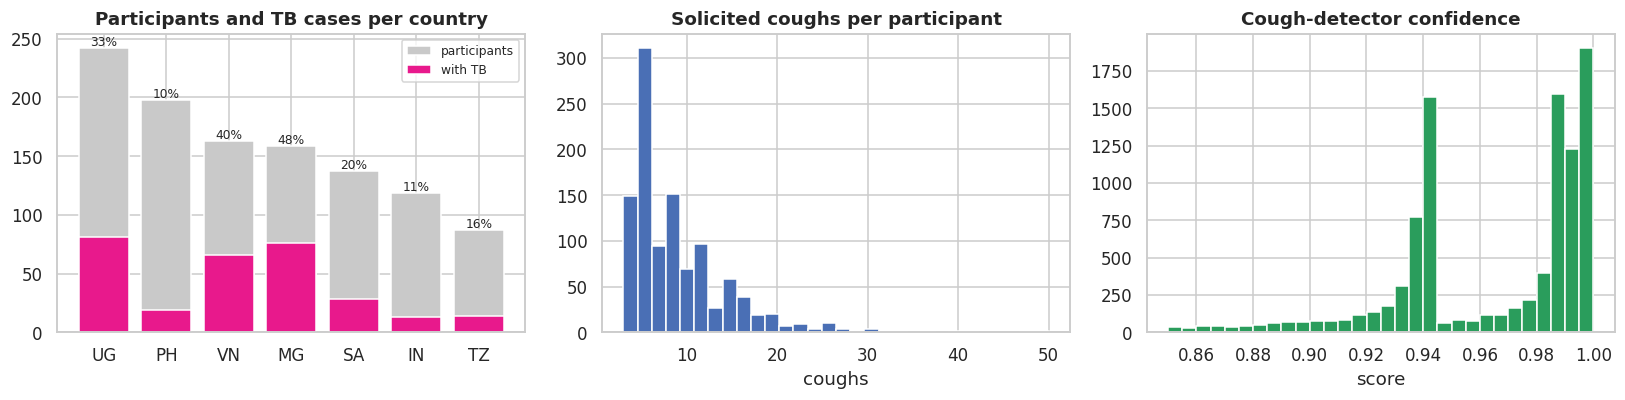

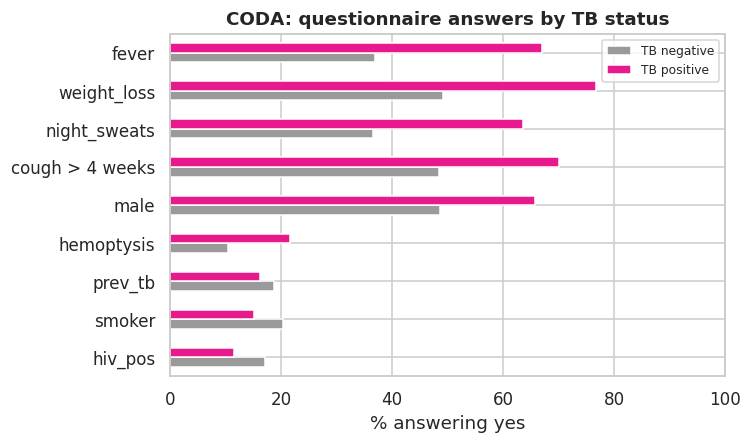

In [4]:
by_c = P.groupby("country").agg(participants=("label", "size"), TB=("label", "sum"), TB_rate=("label", "mean"),
                                coughs=("n_coughs", "sum"), median_coughs=("n_coughs", "median")).sort_values("participants", ascending=False)
by_c["TB"] = by_c.TB.astype(int); by_c["TB_rate"] = (by_c.TB_rate * 100).round(1).astype(str) + "%"
display(by_c)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
order = by_c.index
rate = P.groupby("country").label.mean().reindex(order) * 100
axes[0].bar(order, P.groupby("country").size().reindex(order), color="#c9c9c9", label="participants")
axes[0].bar(order, P.groupby("country").label.sum().reindex(order), color="#e8198c", label="with TB")
axes[0].set(title="Participants and TB cases per country"); axes[0].legend(fontsize=8)
for i, (c, r) in enumerate(rate.items()):
    axes[0].text(i, P.groupby("country").size()[c] + 2, f"{r:.0f}%", ha="center", fontsize=8)
axes[1].hist(P.n_coughs[P.n_coughs > 0], bins=30, color="#4a6fb5"); axes[1].set(title="Solicited coughs per participant", xlabel="coughs")
axes[2].hist(sol.sound_prediction_score, bins=30, color="#2a9d5c"); axes[2].set(title="Cough-detector confidence", xlabel="score")
plt.tight_layout(); plt.show()

BIN = ["male", "smoker", "hiv_pos", "prev_tb", "fever", "weight_loss", "night_sweats", "hemoptysis"]
r = P.groupby("label")[BIN].mean().T * 100
r.loc["cough > 4 weeks"] = P.assign(c=P.cough_days > 28).groupby("label").c.mean() * 100
r = r.rename(columns={0: "TB negative", 1: "TB positive"})
r = r.loc[(r["TB positive"] - r["TB negative"]).sort_values().index]
ax = r.plot.barh(figsize=(7, 4.2), color=["#9a9a9a", "#e8198c"])
ax.set(title="CODA: questionnaire answers by TB status", xlabel="% answering yes", xlim=(0, 100)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Step 4. Test groups for leave-one-country-out

Each country becomes one held-out test group. A country with fewer than `MIN_TB_PER_GROUP` TB cases gives an unstable AUROC, so, as planned in the proposal, the smallest countries are merged until every group reaches the minimum. The random-split folds used in Step 7 are also fixed here, stratified by country and TB status, and saved so every later notebook uses the same groups.

In [5]:
PA = P[P.n_coughs > 0].copy()                    # participants with audio: every model is compared on exactly these people
tb_by_c = PA.groupby("country").label.sum().sort_values()
groups, pending = {}, []
for c, n_tb in tb_by_c.items():
    pending.append(c)
    if PA[PA.country.isin(pending)].label.sum() >= CFG["MIN_TB_PER_GROUP"]:
        groups[" + ".join(pending)] = list(pending); pending = []
if pending:                                       # leftovers join the smallest finished group
    smallest = min(groups, key=lambda g: PA[PA.country.isin(groups[g])].label.sum()) if groups else None
    if smallest:
        new = groups.pop(smallest) + pending; groups[" + ".join(new)] = new
    else:
        groups[" + ".join(pending)] = pending
GROUP_OF = {c: g for g, cs in groups.items() for c in cs}
PA["group"] = PA.country.map(GROUP_OF)
gt = PA.groupby("group").agg(participants=("label", "size"), TB=("label", "sum")).astype(int)
print("Held-out groups for leave-one-country-out:"); display(gt)

PA["rfold"] = -1
strat = PA.country + "_" + PA.label.astype(int).astype(str)
for k, (_, te) in enumerate(StratifiedKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"]).split(PA.index, strat)):
    PA.iloc[te, PA.columns.get_loc("rfold")] = k
PA[["country", "group", "rfold", "label"]].to_csv(OUT / "coda_folds.csv")
print(f"Saved the folds for {len(PA):,} participants to outputs_coda/coda_folds.csv")

Held-out groups for leave-one-country-out:


,participants,TB
group,,
IN + TZ,205,27
MG,157,75
PH,191,19
SA,135,28
UG,233,78
VN,161,64


Saved the folds for 1,082 participants to outputs_coda/coda_folds.csv


## Step 5. Load and check the coughs

The 9,772 files are downloaded in parallel and cached for this session. Each clip is converted to 16 kHz mono and trimmed or padded to exactly `CLIP_SECONDS` (0.5 s, CODA's native length), so later notebooks can apply the **same window** to Zambia and Kenya, which removes the clip-length shortcut found earlier. The waveforms are kept for the Week 2 encoders (HeAR and OPERA).

In [6]:
# VGGish input front end, ported from Google's AudioSet mel_features.py / vggish_input.py
# (Apache License 2.0), exactly as used to produce TBscreen's stored features.
import numpy as np
import librosa

VGG_SR, VGG_WIN_S, VGG_HOP_S = 16000, 0.025, 0.010
VGG_MELS, VGG_FMIN, VGG_FMAX, VGG_LOG_OFFSET = 64, 125.0, 7500.0, 0.01
VGG_FRAMES = 96


def _frame(data, window_length, hop_length):
    n = 1 + int(np.floor((data.shape[0] - window_length) / hop_length))
    if n < 1:
        raise ValueError(f"signal too short: {data.shape[0]} samples < window {window_length}")
    shape = (n, window_length) + data.shape[1:]
    strides = (data.strides[0] * hop_length,) + data.strides
    return np.lib.stride_tricks.as_strided(data, shape=shape, strides=strides)


def _periodic_hann(n):
    return 0.5 - 0.5 * np.cos(2 * np.pi / n * np.arange(n))


def _hz_to_mel(f):
    return 1127.0 * np.log(1.0 + f / 700.0)


def _mel_matrix(num_mel_bins, num_spectrogram_bins, sr, lo, hi):
    nyq = sr / 2.0
    bins_mel = _hz_to_mel(np.linspace(0.0, nyq, num_spectrogram_bins))
    edges = np.linspace(_hz_to_mel(lo), _hz_to_mel(hi), num_mel_bins + 2)
    m = np.empty((num_spectrogram_bins, num_mel_bins))
    for i in range(num_mel_bins):
        l, c, u = edges[i:i + 3]
        m[:, i] = np.maximum(0.0, np.minimum((bins_mel - l) / (c - l), (u - bins_mel) / (u - c)))
    m[0, :] = 0.0
    return m


def log_mel(data, sr=VGG_SR):
    win = int(round(sr * VGG_WIN_S)); hop = int(round(sr * VGG_HOP_S))
    fft = 2 ** int(np.ceil(np.log(win) / np.log(2.0)))
    frames = _frame(np.ascontiguousarray(data, dtype=np.float64), win, hop)
    spec = np.abs(np.fft.rfft(frames * _periodic_hann(win), fft))
    mel = spec @ _mel_matrix(VGG_MELS, spec.shape[1], sr, VGG_FMIN, VGG_FMAX)
    return np.log(mel + VGG_LOG_OFFSET)


def vggish_examples(wave, sr):
    """Waveform -> array (n_examples, 96, 64), as vggish_input.waveform_to_examples."""
    wave = np.asarray(wave, dtype=np.float64)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    if sr != VGG_SR:
        wave = librosa.resample(wave, orig_sr=sr, target_sr=VGG_SR)
    lm = log_mel(wave, VGG_SR)
    return np.ascontiguousarray(_frame(lm, VGG_FRAMES, VGG_FRAMES), dtype=np.float32)


def vggish_example_padded(wave, sr, seconds=1.0):
    """Centre a short clip in `seconds` of zeros (as TBscreen did) and return one (96, 64) example."""
    wave = np.asarray(wave, dtype=np.float64)
    if wave.ndim > 1:
        wave = wave.mean(axis=1)
    if sr != VGG_SR:
        wave = librosa.resample(wave, orig_sr=sr, target_sr=VGG_SR)
    n = int(round(VGG_SR * seconds))
    wave = librosa.util.pad_center(wave[:n], size=n, mode="constant") if len(wave) < n else wave[:n]
    return vggish_examples(wave, VGG_SR)[0]


CLIP_N = int(round(VGG_SR * CFG["CLIP_SECONDS"]))
def to_clip(b):
    w, sr = sf.read(io.BytesIO(b), dtype="float32", always_2d=True)
    w = w.mean(axis=1)
    dur = len(w) / sr
    if sr != VGG_SR:
        w = librosa.resample(w, orig_sr=sr, target_sr=VGG_SR)
    if len(w) >= CLIP_N:                             # keep the loudest CLIP_N window (CODA clips are already 0.5 s)
        e = np.convolve(w ** 2, np.ones(CLIP_N), "valid"); s = int(np.argmax(e)); w = w[s:s + CLIP_N]
    else:
        w = np.pad(w, ((CLIP_N - len(w)) // 2, CLIP_N - len(w) - (CLIP_N - len(w)) // 2))
    return w.astype(np.float32), sr, dur

wf, idf = CACHE / f"coda_wave_{len(sol)}.npy", CACHE / f"coda_index_{len(sol)}.csv"
if wf.exists() and idf.exists():
    WAVE, C = np.load(wf), pd.read_csv(idf)
    print(f"Loaded {len(C):,} cached coughs")
else:
    got = fetch_many(sol.blob.tolist(), to_clip, label="coughs")
    ok = sol.blob.map(lambda n: got.get(n) is not None)
    C = sol[ok].reset_index(drop=True)
    C["orig_sr"] = [got[n][1] for n in C.blob]; C["orig_seconds"] = [round(got[n][2], 3) for n in C.blob]
    WAVE = np.stack([got[n][0] for n in C.blob])
    np.save(wf, WAVE); C.to_csv(idf, index=False)
C = C[C.participant.isin(PA.index)].reset_index(drop=True) if "participant" in C else C
C["label"] = C.participant.map(PA.label).astype(int); C["country"] = C.participant.map(PA.country)
print(f"Coughs: {WAVE.shape} | original sample rates {C.orig_sr.value_counts().to_dict()} | "
      f"original lengths: {C.orig_seconds.round(2).value_counts().head(3).to_dict()}")

  coughs: 977/9,772 in 23 s
  coughs: 1,954/9,772 in 28 s
  coughs: 2,931/9,772 in 34 s
  coughs: 3,908/9,772 in 39 s
  coughs: 4,885/9,772 in 45 s
  coughs: 5,862/9,772 in 50 s
  coughs: 6,839/9,772 in 56 s
  coughs: 7,816/9,772 in 61 s
  coughs: 8,793/9,772 in 67 s
  coughs: 9,770/9,772 in 73 s
  coughs: 9,772/9,772 in 73 s
Coughs: (9772, 8000) | original sample rates {44100: 9772} | original lengths: {0.5: 9641, 0.42: 44, 0.46: 38}


## Step 6. Three representations of each cough

* **MFCC summary:** the mean and spread of 20 mel-frequency cepstral coefficients, the classic hand-crafted cough features and our stand-in for the proposal's arm A1.
* **Spectrogram summary:** the mean and spread of each of VGGish's 64 mel bands.
* **VGGish (pretrained):** 128 numbers from the general-purpose audio network, with no TB training. Each 0.5 s clip is centred in one second of silence, the length VGGish expects.

The **Week 2 encoders** (HeAR, OPERA) plug in here: add a function that turns `WAVE` into one row per cough, and every later step uses it automatically.

In [7]:
def mfcc_summary(W):
    out = []
    for w in W:
        m = librosa.feature.mfcc(y=w, sr=VGG_SR, n_mfcc=20, n_fft=400, hop_length=160)
        out.append(np.r_[m.mean(axis=1), m.std(axis=1)])
    return np.asarray(out, dtype=np.float32)

X_IN = np.stack([vggish_example_padded(w, VGG_SR, seconds=1.0) for w in WAVE]).astype(np.float32)
FEATS = {"MFCC summary": mfcc_summary(WAVE),
         "Spectrogram summary": np.concatenate([X_IN.mean(axis=1), X_IN.std(axis=1)], axis=1)}

VGGISH_URL = "https://github.com/harritaylor/torchvggish/releases/download/v0.1/vggish-10086976.pth"
if TORCH_OK:
    class VGGishBackbone(nn.Module):
        def __init__(self):
            super().__init__()
            def conv(cin, cout):
                return [nn.Conv2d(cin, cout, 3, 1, 1), nn.ReLU(inplace=True)]
            self.features = nn.Sequential(*conv(1, 64), nn.MaxPool2d(2, 2), *conv(64, 128), nn.MaxPool2d(2, 2),
                                          *conv(128, 256), *conv(256, 256), nn.MaxPool2d(2, 2),
                                          *conv(256, 512), *conv(512, 512), nn.MaxPool2d(2, 2))
            self.embeddings = nn.Sequential(nn.Linear(512 * 24, 4096), nn.ReLU(True), nn.Linear(4096, 4096), nn.ReLU(True),
                                            nn.Linear(4096, 128), nn.ReLU(True))
        def forward(self, x):
            x = self.features(x).permute(0, 2, 3, 1).contiguous()
            return self.embeddings(x.view(x.size(0), -1))
    def vggish_embed(X, batch=256):
        wpath = WORK / "vggish-10086976.pth"
        if not wpath.exists():
            torch.hub.download_url_to_file(VGGISH_URL, str(wpath), hash_prefix="10086976")
        try:
            sd = torch.load(wpath, map_location="cpu", weights_only=True)
        except TypeError:
            sd = torch.load(wpath, map_location="cpu")
        bb = VGGishBackbone(); bb.load_state_dict(sd, strict=True); bb.eval().to(DEVICE)
        out = []
        with torch.no_grad():
            for i in range(0, len(X), batch):
                out.append(bb(torch.as_tensor(X[i:i + batch], device=DEVICE)[:, None]).cpu().numpy())
        return np.concatenate(out).astype(np.float32)
    ef = CACHE / f"coda_vggish_{len(C)}.npy"
    FEATS["VGGish (pretrained)"] = np.load(ef) if ef.exists() else vggish_embed(X_IN)
    np.save(ef, FEATS["VGGish (pretrained)"])
PRIMARY = "VGGish (pretrained)" if TORCH_OK else "Spectrogram summary"
print("Representations:", {k: v.shape for k, v in FEATS.items()}, "| primary:", PRIMARY)

100%|██████████| 275M/275M [00:05<00:00, 49.1MB/s] 


Representations: {'MFCC summary': (9772, 40), 'Spectrogram summary': (9772, 128), 'VGGish (pretrained)': (9772, 128)} | primary: VGGish (pretrained)


In [8]:
def logit(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-4, 1 - 1e-4); return np.log(p / (1 - p))

def lr_pipe(C, impute=False):
    steps = ([SimpleImputer(strategy="median")] if impute else []) + [StandardScaler(),
             LogisticRegression(C=C, max_iter=5000, class_weight="balanced")]
    return make_pipeline(*steps)

def probe(Xtr, ytr, Xte):
    return lr_pipe(CFG["PROBE_C"]).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def part_mean(subjects, p):
    return pd.Series(np.asarray(p, dtype=float)).groupby(np.asarray(subjects)).mean()

def _midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    out = np.empty(N); out[J] = T; return out

def delong(y, p_ref, p_new):
    y = np.asarray(y).astype(int); pos = y == 1; m, n = pos.sum(), (~pos).sum()
    aucs, V10, V01 = [], [], []
    for p in (p_ref, p_new):
        p = np.asarray(p, dtype=float); X, Y = p[pos], p[~pos]
        tx, ty, tz = _midrank(X), _midrank(Y), _midrank(np.r_[X, Y])
        aucs.append((tz[:m].sum() - m * (m + 1) / 2) / (m * n))
        V10.append((tz[:m] - tx) / n); V01.append(1 - (tz[m:] - ty) / m)
    S = np.cov(np.vstack(V10)) / m + np.cov(np.vstack(V01)) / n
    se = np.sqrt(max(S[0, 0] + S[1, 1] - 2 * S[0, 1], 1e-12)); d = aucs[1] - aucs[0]
    return dict(diff=d, lo=d - 1.96 * se, hi=d + 1.96 * se, p=float(2 * norm.sf(abs(d / se))))

def boot_ci(y, p):
    y, p = np.asarray(y), np.asarray(p); r = np.random.default_rng(CFG["SEED"]); out = []
    for _ in range(CFG["N_BOOT"]):
        i = r.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            out.append(roc_auc_score(y[i], p[i]))
    return np.percentile(out, [2.5, 97.5])

def threshold_for(y, p, sens):
    # Highest threshold that still catches `sens` of the TB cases in the training predictions.
    pos = np.sort(np.asarray(p)[np.asarray(y) == 1])
    return pos[min(len(pos) - 1, int(np.floor((1 - sens) * len(pos))))] if len(pos) else 0.5

def run_protocol(P, clips, X, folds, clin_cols, inner_k=4):
    # For each test fold: train B (questions), audio, and A (questions + out-of-fold audio score) on the rest.
    # Thresholds for the target sensitivity are set on TRAINING predictions only (frozen), then applied to the test fold.
    rows = []
    for f in sorted(pd.unique(folds)):
        te, tr = P.index[folds == f], P.index[folds != f]
        ctr, cte = clips.participant.isin(tr).values, clips.participant.isin(te).values
        a_te = part_mean(clips.participant.values[cte], probe(X[ctr], clips.label.values[ctr], X[cte])).reindex(te)
        a_tr = pd.Series(np.nan, index=tr)
        k = min(inner_k, int(P.loc[tr, "label"].value_counts().min()))
        for itr, iva in StratifiedKFold(k, shuffle=True, random_state=CFG["SEED"]).split(tr, P.loc[tr, "label"]):
            mt, mv = clips.participant.isin(tr[itr]).values, clips.participant.isin(tr[iva]).values
            a_tr.update(part_mean(clips.participant.values[mv], probe(X[mt], clips.label.values[mt], X[mv])))
        ytr = P.loc[tr, "label"].values
        res = pd.DataFrame({"label": P.loc[te, "label"].values, "fold": f, "audio": a_te.values}, index=te)
        thr = {"audio": threshold_for(ytr, a_tr.values, CFG["SENSITIVITY_TARGET"])}
        for name, cols in (("B", clin_cols), ("A", None)):
            Xtr = P.loc[tr, clin_cols].values if name == "B" else np.c_[P.loc[tr, clin_cols].values, logit(a_tr.values)]
            Xte = P.loc[te, clin_cols].values if name == "B" else np.c_[P.loc[te, clin_cols].values, logit(a_te.values)]
            m = lr_pipe(CFG["CLIN_C"], impute=True)
            oof = cross_val_predict(m, Xtr, ytr, cv=StratifiedKFold(k, shuffle=True, random_state=CFG["SEED"]), method="predict_proba")[:, 1]
            thr[name] = threshold_for(ytr, oof, CFG["SENSITIVITY_TARGET"])
            res[name] = m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
        for name in ("B", "audio", "A"):
            res[f"{name}_flag"] = (res[name] >= thr[name]).astype(int)
        rows.append(res)
    return pd.concat(rows)

def sens_spec(y, flag):
    y, flag = np.asarray(y), np.asarray(flag)
    return (flag[y == 1].mean() if (y == 1).any() else np.nan), (1 - flag[y == 0].mean() if (y == 0).any() else np.nan)

def summarise(pp, setting):
    rows = []
    for m, lab in (("B", "Questions only (B)"), ("audio", "Cough only"), ("A", "Questions + cough (A)")):
        lo, hi = boot_ci(pp.label, pp[m]); se, sp = sens_spec(pp.label, pp[f"{m}_flag"])
        rows.append({"setting": setting, "model": lab, "AUROC": round(roc_auc_score(pp.label, pp[m]), 3),
                     "95% CI": f"{lo:.2f} to {hi:.2f}", "sensitivity at frozen threshold": round(se, 2),
                     "specificity at frozen threshold": round(sp, 2)})
    d = delong(pp.label, pp.B, pp.A)
    rows.append({"setting": setting, "model": "Gain Δ = A − B", "AUROC": round(d["diff"], 3),
                 "95% CI": f"{d['lo']:+.2f} to {d['hi']:+.2f}", "sensitivity at frozen threshold": f"p = {d['p']:.2f}",
                 "specificity at frozen threshold": ""})
    return pd.DataFrame(rows)

idx_of = C.participant.values
print("Modelling helpers ready.")

Modelling helpers ready.


## Step 7. Random participant split: the in-distribution reference

Participants are split into five folds that mix all countries. This is how most published cough results are measured, so it is our **reference point**: the CODA challenge teams reported AUROC **0.69 to 0.74** for cough alone and **0.78 to 0.83** for cough plus clinical data (on a separate test set, so our numbers are comparable but not identical).

The **threshold** for 90% sensitivity is fixed on each training fold and then applied unchanged to the test fold, as a clinic would have to do.

In [9]:
RANDOM = {}
tabs = []
for fname, F in FEATS.items():
    pp = run_protocol(PA, C, F, PA.rfold.values, CLIN_SETS["shared 9"])
    RANDOM[fname] = pp; tabs.append(summarise(pp, f"random split, {fname}"))
pp_ext = run_protocol(PA, C, FEATS[PRIMARY], PA.rfold.values, CLIN_SETS["extended"])
tabs.append(summarise(pp_ext, f"random split, {PRIMARY}, extended questions").iloc[[0, 2, 3]])
random_table = pd.concat(tabs, ignore_index=True)
display(random_table); random_table.to_csv(OUT / "coda_random_split.csv", index=False)

,setting,model,AUROC,95% CI,sensitivity at frozen threshold,specificity at frozen threshold
0,"random split, MFCC summary",Questions only (B),0.731,0.70 to 0.77,0.91,0.29
1,"random split, MFCC summary",Cough only,0.676,0.64 to 0.71,0.91,0.24
2,"random split, MFCC summary",Questions + cough (A),0.744,0.71 to 0.78,0.91,0.33
3,"random split, MFCC summary",Gain Δ = A − B,0.013,+0.00 to +0.02,p = 0.01,
4,"random split, Spectrogram summary",Questions only (B),0.731,0.70 to 0.77,0.91,0.29
5,"random split, Spectrogram summary",Cough only,0.678,0.64 to 0.71,0.92,0.27
6,"random split, Spectrogram summary",Questions + cough (A),0.745,0.71 to 0.78,0.9,0.34
7,"random split, Spectrogram summary",Gain Δ = A − B,0.013,+0.00 to +0.02,p = 0.00,
8,"random split, VGGish (pretrained)",Questions only (B),0.731,0.70 to 0.77,0.91,0.29
9,"random split, VGGish (pretrained)",Cough only,0.684,0.65 to 0.72,0.92,0.27


## Step 8. Leave-one-country-out: the main experiment

For every held-out group from Step 4, all three models are trained on the **other** countries only and tested on the held-out one. Nothing about the held-out country (scaling, imputation, threshold) is used in training.

**Reported per held-out group:** AUROC for questions (B), cough and combined (A); the gain Δ = A − B with DeLong's 95% interval; and sensitivity and specificity at the frozen threshold. Across groups: the **mean** and **worst** AUROC, and Δ pooled over all held-out participants.

**Which summary to quote.** Each held-out group is scored by a different model, so the pooled AUROC mixes scores that are not on quite the same scale and usually sits a little below the per-group values. The **mean over groups** is the cleaner headline for AUROC; the pooled row is kept for Δ, where both models are compared on the same people.


=== Leave-one-country-out, MFCC summary


,held-out,people,TB,AUROC B,AUROC cough,AUROC A,Δ = A − B (95% CI),A: sens / spec at frozen threshold
0,IN + TZ,205,27,0.691,0.555,0.694,+0.002 (-0.03 to +0.04),0.89 / 0.29
1,MG,157,75,0.762,0.564,0.711,-0.050 (-0.11 to +0.01),1.00 / 0.00
2,PH,191,19,0.642,0.522,0.645,+0.003 (-0.03 to +0.03),0.63 / 0.55
3,SA,135,28,0.591,0.504,0.588,-0.003 (-0.03 to +0.02),0.57 / 0.50
4,UG,233,78,0.677,0.524,0.679,+0.002 (-0.02 to +0.02),0.99 / 0.06
5,VN,161,64,0.780,0.610,0.781,+0.001 (-0.02 to +0.02),0.67 / 0.74
6,ALL (pooled),1082,291,0.707,0.598,0.709,+0.002 (-0.01 to +0.01),0.85 / 0.36
7,mean over groups,,,0.690,0.546,0.683,,
8,worst group,,,0.591,0.504,0.588,,



=== Leave-one-country-out, Spectrogram summary


,held-out,people,TB,AUROC B,AUROC cough,AUROC A,Δ = A − B (95% CI),A: sens / spec at frozen threshold
0,IN + TZ,205,27,0.691,0.516,0.691,-0.000 (-0.03 to +0.03),0.89 / 0.26
1,MG,157,75,0.762,0.556,0.714,-0.048 (-0.11 to +0.01),1.00 / 0.01
2,PH,191,19,0.642,0.513,0.647,+0.005 (-0.02 to +0.03),0.63 / 0.56
3,SA,135,28,0.591,0.565,0.593,+0.002 (-0.02 to +0.02),0.61 / 0.51
4,UG,233,78,0.677,0.485,0.666,-0.011 (-0.04 to +0.02),0.99 / 0.05
5,VN,161,64,0.780,0.577,0.776,-0.004 (-0.02 to +0.01),0.66 / 0.73
6,ALL (pooled),1082,291,0.707,0.603,0.706,-0.000 (-0.01 to +0.01),0.85 / 0.35
7,mean over groups,,,0.690,0.535,0.681,,
8,worst group,,,0.591,0.485,0.593,,



=== Leave-one-country-out, VGGish (pretrained)


,held-out,people,TB,AUROC B,AUROC cough,AUROC A,Δ = A − B (95% CI),A: sens / spec at frozen threshold
0,IN + TZ,205,27,0.691,0.528,0.686,-0.005 (-0.04 to +0.03),0.93 / 0.22
1,MG,157,75,0.762,0.434,0.685,-0.076 (-0.12 to -0.04),1.00 / 0.00
2,PH,191,19,0.642,0.458,0.642,+0.000 (-0.04 to +0.04),0.58 / 0.66
3,SA,135,28,0.591,0.543,0.596,+0.005 (-0.03 to +0.04),0.57 / 0.43
4,UG,233,78,0.677,0.505,0.674,-0.003 (-0.03 to +0.02),0.97 / 0.07
5,VN,161,64,0.780,0.569,0.776,-0.004 (-0.02 to +0.01),0.78 / 0.58
6,ALL (pooled),1082,291,0.707,0.638,0.714,+0.008 (-0.00 to +0.02),0.87 / 0.34
7,mean over groups,,,0.690,0.506,0.676,,
8,worst group,,,0.591,0.434,0.596,,



=== Leave-one-country-out, extended questions (CODA only)


,setting,model,AUROC,95% CI,sensitivity at frozen threshold,specificity at frozen threshold
0,"LOCO, VGGish (pretrained), extended questions",Questions only (B),0.794,0.76 to 0.83,0.91,0.5
2,"LOCO, VGGish (pretrained), extended questions",Questions + cough (A),0.793,0.76 to 0.82,0.9,0.49
3,"LOCO, VGGish (pretrained), extended questions",Gain Δ = A − B,-0.001,-0.00 to +0.00,p = 0.76,


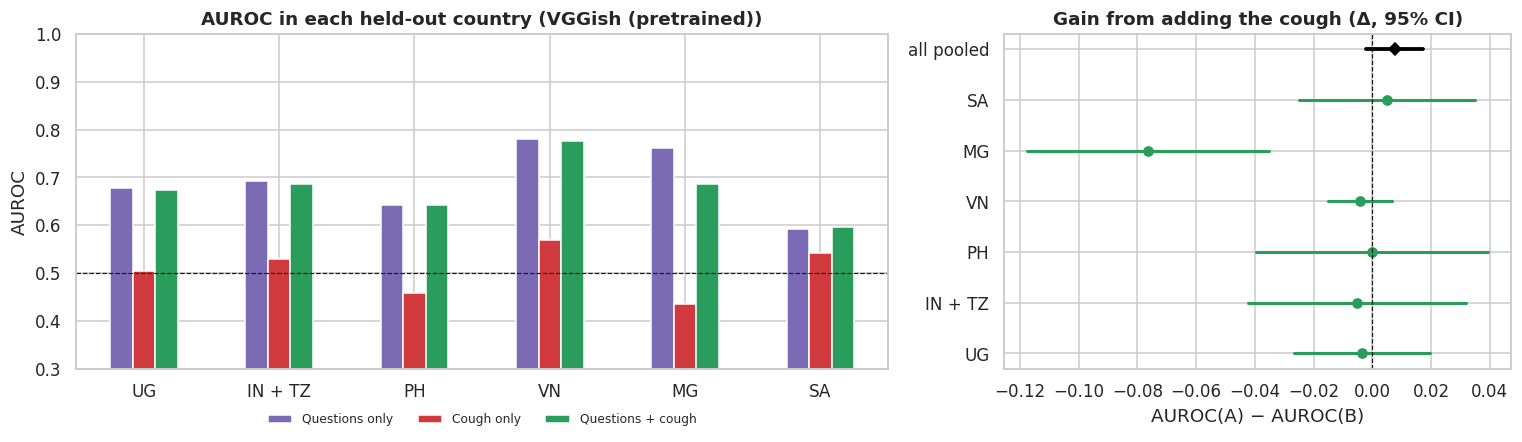

In [10]:
LOCO = {fname: run_protocol(PA, C, F, PA.group.values, CLIN_SETS["shared 9"]) for fname, F in FEATS.items()}
LOCO_EXT = run_protocol(PA, C, FEATS[PRIMARY], PA.group.values, CLIN_SETS["extended"])

def loco_table(pp, fname):
    rows = []
    for g, d in pp.groupby("fold"):
        if d.label.nunique() < 2:
            continue
        dl = delong(d.label, d.B, d.A)
        row = {"held-out": g, "people": len(d), "TB": int(d.label.sum())}
        for m, lab in (("B", "B"), ("audio", "cough"), ("A", "A")):
            row[f"AUROC {lab}"] = round(roc_auc_score(d.label, d[m]), 3)
        row["Δ = A − B (95% CI)"] = f"{dl['diff']:+.3f} ({dl['lo']:+.2f} to {dl['hi']:+.2f})"
        se, sp = sens_spec(d.label, d.A_flag); row["A: sens / spec at frozen threshold"] = f"{se:.2f} / {sp:.2f}"
        rows.append(row)
    t = pd.DataFrame(rows)
    dl = delong(pp.label, pp.B, pp.A)
    summary = {"held-out": "ALL (pooled)", "people": len(pp), "TB": int(pp.label.sum()),
               "AUROC B": round(roc_auc_score(pp.label, pp.B), 3), "AUROC cough": round(roc_auc_score(pp.label, pp.audio), 3),
               "AUROC A": round(roc_auc_score(pp.label, pp.A), 3),
               "Δ = A − B (95% CI)": f"{dl['diff']:+.3f} ({dl['lo']:+.2f} to {dl['hi']:+.2f})",
               "A: sens / spec at frozen threshold": "{:.2f} / {:.2f}".format(*sens_spec(pp.label, pp.A_flag))}
    mean = {"held-out": "mean over groups", **{k: round(t[k].mean(), 3) for k in ("AUROC B", "AUROC cough", "AUROC A")}}
    worst = {"held-out": "worst group", **{k: round(t[k].min(), 3) for k in ("AUROC B", "AUROC cough", "AUROC A")}}
    out = pd.concat([t, pd.DataFrame([summary, mean, worst])], ignore_index=True)
    for col in ("people", "TB"):
        out[col] = out[col].map(lambda v: "" if pd.isna(v) else str(int(v)))
    return out.fillna("")

for fname in FEATS:
    print(f"\n=== Leave-one-country-out, {fname}")
    t = loco_table(LOCO[fname], fname); display(t)
    t.to_csv(OUT / f"coda_loco_{re.sub(r'[^a-z0-9]+', '_', fname.lower())}.csv", index=False)
print("\n=== Leave-one-country-out, extended questions (CODA only)")
display(summarise(LOCO_EXT, f"LOCO, {PRIMARY}, extended questions").iloc[[0, 2, 3]])

pp = LOCO[PRIMARY]
groups_order = PA.groupby("group").size().sort_values(ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
au = pd.DataFrame({m: pp.groupby("fold").apply(lambda d: roc_auc_score(d.label, d[m]) if d.label.nunique() == 2 else np.nan)
                   for m in ("B", "audio", "A")}).reindex(groups_order)
au.columns = ["Questions only", "Cough only", "Questions + cough"]
au.plot.bar(ax=axes[0], color=["#7b6bb5", "#d03a3f", "#2a9d5c"], rot=0)
axes[0].axhline(0.5, color="k", ls="--", lw=0.8)
axes[0].set(title=f"AUROC in each held-out country ({PRIMARY})", ylabel="AUROC", ylim=(0.3, 1.0), xlabel="")
axes[0].legend(fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1), frameon=False)
ds = [(g, delong(d.label, d.B, d.A)) for g, d in pp.groupby("fold") if d.label.nunique() == 2]
ds = sorted(ds, key=lambda t: list(groups_order).index(t[0]))
for i, (g, d) in enumerate(ds):
    axes[1].plot([d["lo"], d["hi"]], [i, i], color="#2a9d5c", lw=2); axes[1].plot(d["diff"], i, "o", color="#2a9d5c")
dl = delong(pp.label, pp.B, pp.A)
axes[1].plot([dl["lo"], dl["hi"]], [len(ds), len(ds)], color="black", lw=2.5); axes[1].plot(dl["diff"], len(ds), "D", color="black")
axes[1].axvline(0, color="k", ls="--", lw=0.8)
axes[1].set_yticks(range(len(ds) + 1)); axes[1].set_yticklabels([g for g, _ in ds] + ["all pooled"])
axes[1].set(title="Gain from adding the cough (Δ, 95% CI)", xlabel="AUROC(A) − AUROC(B)")
plt.tight_layout(); plt.show()

## Step 9. How optimistic is the random split, and does a cough reveal its country?

**Optimism.** For each model, the difference between the random-split AUROC (Step 7) and the leave-one-country-out AUROC (Step 8). A large drop for the cough model but a small one for the questions would repeat the Zambia and Kenya pattern within a single, consistent study.

**Country signature.** As in Notebook 03, a linear classifier tries to name the country from a single cough, always on participants it has never seen. Because CODA used the same app everywhere, a strong result here cannot be blamed on different clip preparation.

,features,model,random split,leave-one-country-out,drop
0,MFCC summary,Questions only,0.731,0.707,0.025
1,MFCC summary,Cough only,0.676,0.598,0.078
2,MFCC summary,Questions + cough,0.744,0.709,0.035
3,Spectrogram summary,Questions only,0.731,0.707,0.025
4,Spectrogram summary,Cough only,0.678,0.603,0.076
5,Spectrogram summary,Questions + cough,0.745,0.706,0.038
6,VGGish (pretrained),Questions only,0.731,0.707,0.025
7,VGGish (pretrained),Cough only,0.684,0.638,0.045
8,VGGish (pretrained),Questions + cough,0.745,0.714,0.031


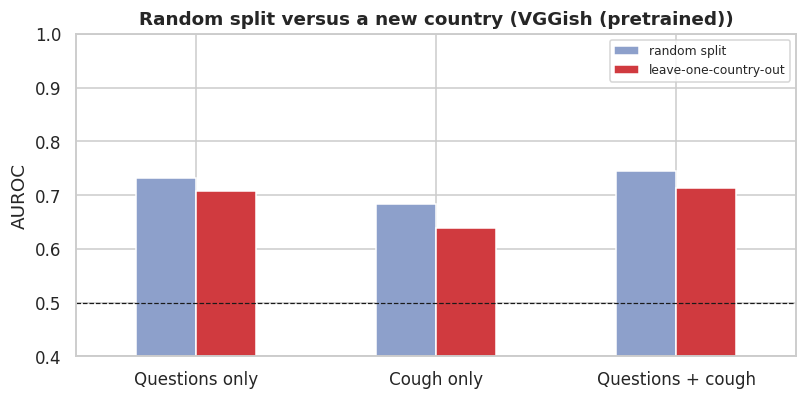

,features,country: accuracy (chance 0.14),country: AUROC,TB: AUROC per person
0,MFCC summary,0.732,0.943,0.666
1,Spectrogram summary,0.717,0.938,0.669
2,VGGish (pretrained),0.613,0.900,0.675


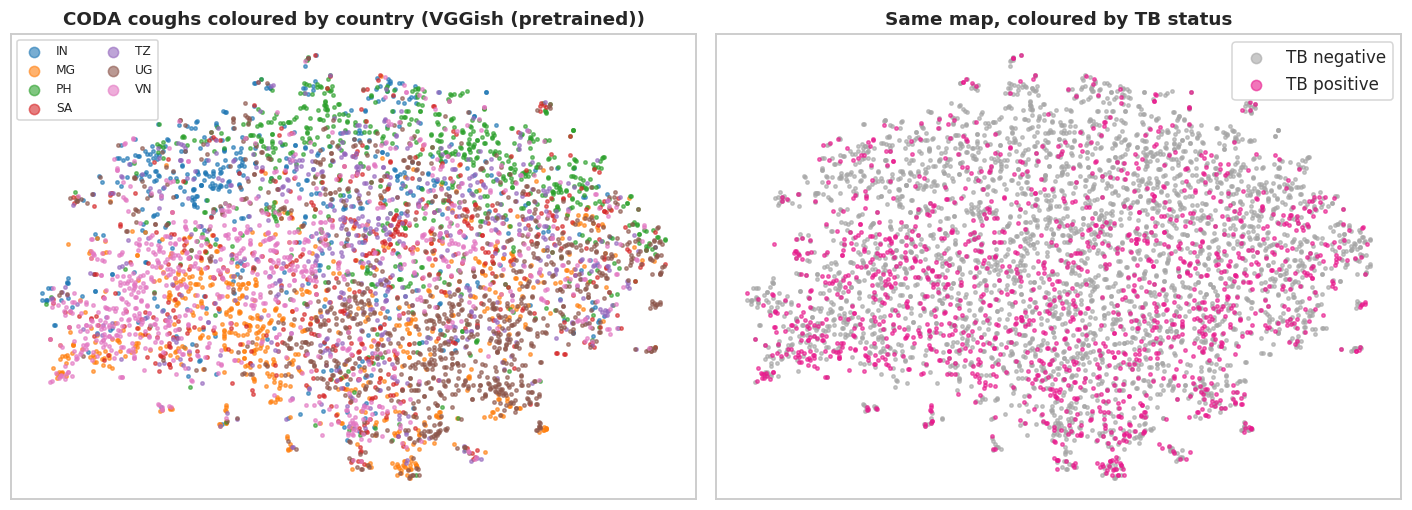

In [11]:
opt_rows = []
for fname in FEATS:
    for m, lab in (("B", "Questions only"), ("audio", "Cough only"), ("A", "Questions + cough")):
        r_ = roc_auc_score(RANDOM[fname].label, RANDOM[fname][m]); l_ = roc_auc_score(LOCO[fname].label, LOCO[fname][m])
        opt_rows.append({"features": fname, "model": lab, "random split": round(r_, 3), "leave-one-country-out": round(l_, 3),
                         "drop": round(r_ - l_, 3)})
optimism = pd.DataFrame(opt_rows); display(optimism); optimism.to_csv(OUT / "coda_optimism.csv", index=False)
o = optimism[optimism.features == PRIMARY].set_index("model")[["random split", "leave-one-country-out"]]
ax = o.plot.bar(figsize=(7.5, 3.8), color=["#8da0cb", "#d03a3f"], rot=0)
ax.axhline(0.5, color="k", ls="--", lw=0.8); ax.set(title=f"Random split versus a new country ({PRIMARY})", ylabel="AUROC", ylim=(0.4, 1.0), xlabel="")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

countries = sorted(C.country.unique())
cv = StratifiedGroupKFold(CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"])
probe_rows = []
for fname, F in FEATS.items():
    pc = cross_val_predict(lr_pipe(CFG["PROBE_C"]), F, C.country, cv=cv, groups=idx_of, method="predict_proba")
    pt = cross_val_predict(lr_pipe(CFG["PROBE_C"]), F, C.label, cv=cv, groups=idx_of, method="predict_proba")[:, 1]
    per = part_mean(idx_of, pt); yl = PA.label.reindex(per.index)
    probe_rows.append({"features": fname, f"country: accuracy (chance {1 / len(countries):.2f})":
                       round(balanced_accuracy_score(C.country, np.array(countries)[pc.argmax(1)]), 3),
                       "country: AUROC": round(roc_auc_score(C.country, pc, multi_class="ovr", labels=countries), 3),
                       "TB: AUROC per person": round(roc_auc_score(yl, per), 3)})
country_probe = pd.DataFrame(probe_rows); display(country_probe); country_probe.to_csv(OUT / "coda_country_vs_tb_probe.csv", index=False)

sub = rng.choice(len(C), min(len(C), 5000), replace=False)
Z = TSNE(2, perplexity=min(30, max(5, len(sub) // 4)), init="pca", random_state=CFG["SEED"]).fit_transform(
    StandardScaler().fit_transform(FEATS[PRIMARY][sub]))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
pal = dict(zip(countries, sns.color_palette("tab10", len(countries))))
for c in countries:
    m = C.country.values[sub] == c
    axes[0].scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.6, color=pal[c], label=c)
axes[0].set(title=f"CODA coughs coloured by country ({PRIMARY})", xticks=[], yticks=[]); axes[0].legend(markerscale=3, fontsize=8, ncol=2)
for v, col, lab in ((0, "#a5a5a5", "TB negative"), (1, "#e8198c", "TB positive")):
    m = C.label.values[sub] == v
    axes[1].scatter(Z[m, 0], Z[m, 1], s=5, alpha=0.6, color=col, label=lab)
axes[1].set(title="Same map, coloured by TB status", xticks=[], yticks=[]); axes[1].legend(markerscale=3)
plt.tight_layout(); plt.show()

## Step 10. Summary and export

The headline numbers go into one table and `summary.json`. The bundle `coda_results.zip` contains **only aggregate tables and figures**. Audio, embeddings and per-participant predictions stay inside this private session, as the data use statement requires.

In [12]:
pp = LOCO[PRIMARY]; dl = delong(pp.label, pp.B, pp.A); rp = RANDOM[PRIMARY]; dr = delong(rp.label, rp.B, rp.A)
lt = loco_table(pp, PRIMARY); per_group = lt[~lt["held-out"].isin(["ALL (pooled)", "mean over groups", "worst group"])]
summary = {
    "participants with coughs": len(PA), "TB positive": int(PA.label.sum()), "coughs": len(C),
    "countries": countries, "held-out groups": list(gt.index), "clinical variables (shared 9)": CLIN_SETS["shared 9"],
    "features": PRIMARY,
    "random split B / cough / A": f"{roc_auc_score(rp.label, rp.B):.3f} / {roc_auc_score(rp.label, rp.audio):.3f} / {roc_auc_score(rp.label, rp.A):.3f}",
    "random split gain A-B": f"{dr['diff']:+.3f} ({dr['lo']:+.2f} to {dr['hi']:+.2f}), p={dr['p']:.2f}",
    "LOCO pooled B / cough / A": f"{roc_auc_score(pp.label, pp.B):.3f} / {roc_auc_score(pp.label, pp.audio):.3f} / {roc_auc_score(pp.label, pp.A):.3f}",
    "LOCO gain A-B": f"{dl['diff']:+.3f} ({dl['lo']:+.2f} to {dl['hi']:+.2f}), p={dl['p']:.2f}",
    "LOCO worst-group AUROC B / cough / A": f"{per_group['AUROC B'].min():.3f} / {per_group['AUROC cough'].min():.3f} / {per_group['AUROC A'].min():.3f}",
    "country recognisable from one cough (AUROC)": float(country_probe.set_index("features").loc[PRIMARY, "country: AUROC"]),
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
display(pd.Series(summary, name="value").to_frame())

bundle = WORK / "export" / "coda_results.zip"; bundle.parent.mkdir(exist_ok=True)
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT.rglob("*")):
        if f.is_file() and f.name != "coda_folds.csv":          # folds list participant IDs: keep them private too
            z.write(f, f"outputs/{f.relative_to(OUT).as_posix()}")
    if CFG["EXPORT_EMBEDDINGS"]:
        for f in sorted(CACHE.glob("coda_vggish_*.npy")):
            z.write(f, f"embeddings/{f.name}")
print(f"Saved {bundle} ({bundle.stat().st_size / 1e6:.1f} MB): aggregate tables and figures only")

,value
participants with coughs,1082
TB positive,291
coughs,9772
countries,"[IN, MG, PH, SA, TZ, UG, VN]"
held-out groups,"[IN + TZ, MG, PH, SA, UG, VN]"
clinical variables (shared 9),"[age, male, smoker, hiv_pos, prev_tb, cough_da..."
features,VGGish (pretrained)
random split B / cough / A,0.731 / 0.684 / 0.745
random split gain A-B,"+0.014 (+0.00 to +0.02), p=0.01"
LOCO pooled B / cough / A,0.707 / 0.638 / 0.714


Saved /kaggle/working/export/coda_results.zip (0.8 MB): aggregate tables and figures only


## How to read the results

1. **Random split (Step 7).** Cough alone near 0.69 to 0.74 and combined near 0.78 to 0.83 would match the challenge, confirming the pipeline reads CODA correctly.
2. **The main answer (Step 8).** Look at Δ pooled and per country. An interval that includes zero means that, for a new country, the cough adds nothing detectable to the questions.
3. **Worst country.** Clinics care about the country where a tool fails, not the average.
4. **Optimism (Step 9).** A large random-to-new-country drop for cough but not for questions repeats, within one consistent study, what Zambia and Kenya showed.
5. **Country signature (Step 9).** If the country is easy to tell from one cough even though every country used the same app, the signature comes from people, rooms or phones, not from data preparation.